In [1]:
import pandas as pd

# Read the text file into a DataFrame
data = pd.read_csv('Helium_S_data.txt', delimiter='\s+')

# Display the data
print(data)

     Wave_L  Intensity
0    339.79    1315.25
1    340.17    1315.25
2    340.55    1315.25
3    340.93    1383.52
4    341.31    1406.27
..      ...        ...
429  499.21    1538.25
430  499.57    1656.58
431  499.93    2380.19
432  500.30    4921.95
433  500.66   10157.92

[434 rows x 2 columns]


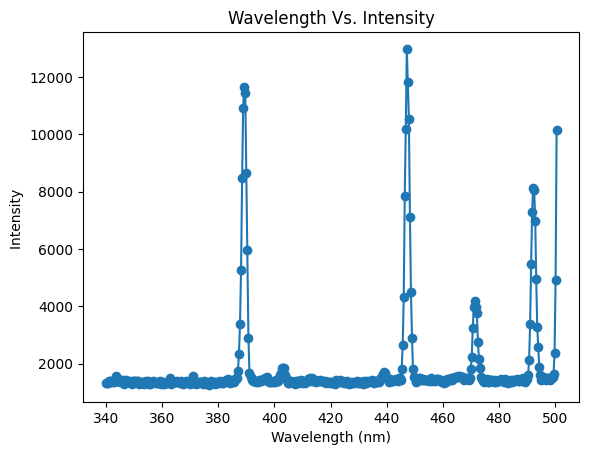

In [3]:
import matplotlib.pyplot as plt

# Plot the data
plt.plot(data['Wave_L'], data['Intensity'], marker='o')

# Add labels and title
plt.xlabel('Wavelength (nm)')
plt.ylabel('Intensity ')
plt.title('Wavelength Vs. Intensity')

# Show the plot
plt.show()

     Wave_L  Intensity
0    339.79    1315.25
1    340.17    1315.25
2    340.55    1315.25
3    340.93    1383.52
4    341.31    1406.27
..      ...        ...
429  499.21    1538.25
430  499.57    1656.58
431  499.93    2380.19
432  500.30    4921.95
433  500.66   10157.92

[434 rows x 2 columns]


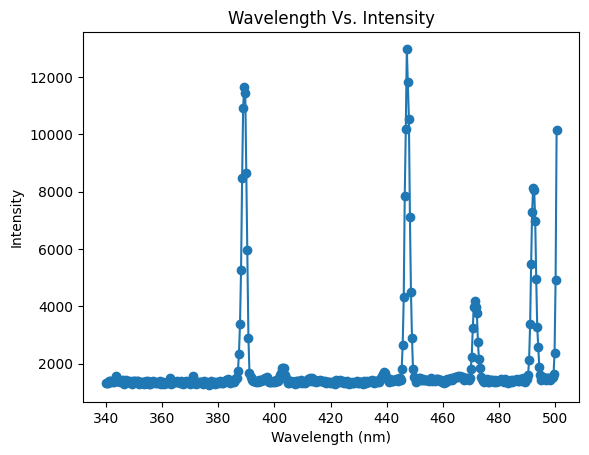

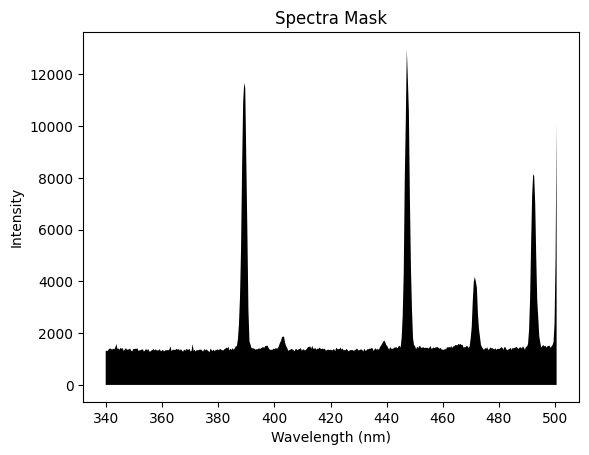

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read the text file into a DataFrame
data = pd.read_csv('Helium_S_data.txt', delimiter='\s+')

# Extract the wavelength and intensity data
wavelength = data['Wave_L'].values
intensity = data['Intensity'].values

# Define the intensity thresholds
lower_threshold = 20
upper_threshold = 80

# Function to create the spectra mask
def create_spectra_mask(wavelength, intensity, lower_threshold, upper_threshold):
    """
    Creates a spectra mask by blacking out regions outside the intensity thresholds and
    highlighting regions within the thresholds.

    Parameters:
        wavelength (np.ndarray): Array of wavelength values.
        intensity (np.ndarray): Array of intensity values.
        lower_threshold (float): Lower intensity threshold.
        upper_threshold (float): Upper intensity threshold.

    Returns:
        None
    """
    # Create a mask for the regions within the specified intensity thresholds
    mask = (intensity >= lower_threshold) & (intensity <= upper_threshold)

    # Create a figure and axis
    fig, ax = plt.subplots()

    # Plot the spectra mask
    ax.fill_between(wavelength, 0, intensity, where=mask, facecolor='blue', interpolate=True)
    
    # Plot the regions outside the mask as black
    ax.fill_between(wavelength, 0, intensity, where=~mask, facecolor='black', interpolate=True)
    
    # Set labels and title
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel('Intensity')
    ax.set_title('Spectra Mask')

    # Show the plot
    plt.show()

# Display the original data
print(data)

# Plot the original data
plt.plot(data['Wave_L'], data['Intensity'], marker='o')
plt.xlabel('Wavelength (nm)')
plt.ylabel('Intensity')
plt.title('Wavelength Vs. Intensity')
plt.show()

# Create the spectra mask
create_spectra_mask(wavelength, intensity, lower_threshold, upper_threshold)


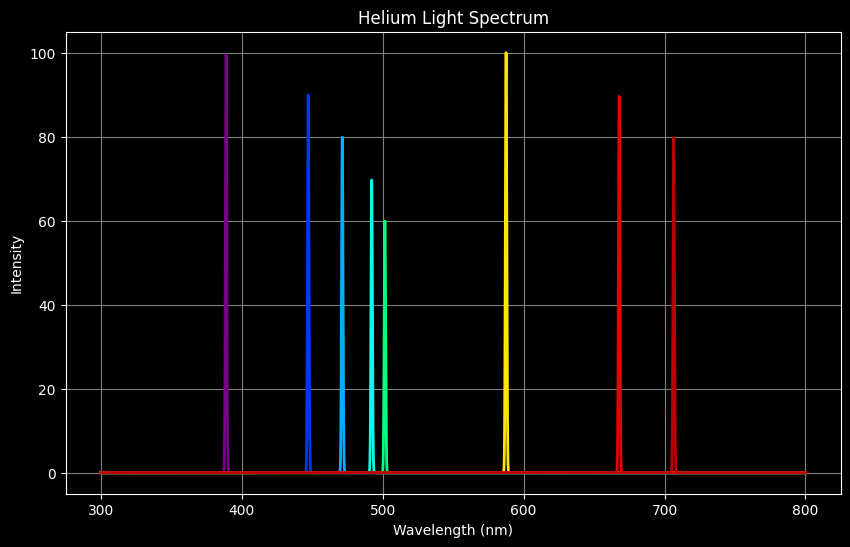

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def wavelength_to_rgb(wavelength):
    """Converts a wavelength in nm to an RGB color."""
    gamma = 0.8
    intensity_max = 255
    factor = 0.0
    R = G = B = 0
    
    if (wavelength >= 380) and (wavelength < 440):
        R = -(wavelength - 440) / (440 - 380)
        G = 0.0
        B = 1.0
    elif (wavelength >= 440) and (wavelength < 490):
        R = 0.0
        G = (wavelength - 440) / (490 - 440)
        B = 1.0
    elif (wavelength >= 490) and (wavelength < 510):
        R = 0.0
        G = 1.0
        B = -(wavelength - 510) / (510 - 490)
    elif (wavelength >= 510) and (wavelength < 580):
        R = (wavelength - 510) / (580 - 510)
        G = 1.0
        B = 0.0
    elif (wavelength >= 580) and (wavelength < 645):
        R = 1.0
        G = -(wavelength - 645) / (645 - 580)
        B = 0.0
    elif (wavelength >= 645) and (wavelength <= 780):
        R = 1.0
        G = 0.0
        B = 0.0
    
    if (wavelength >= 380) and (wavelength < 420):
        factor = 0.3 + 0.7*(wavelength - 380) / (420 - 380)
    elif (wavelength >= 420) and (wavelength < 645):
        factor = 1.0
    elif (wavelength >= 645) and (wavelength <= 780):
        factor = 0.3 + 0.7*(780 - wavelength) / (780 - 645)
    
    R = round(intensity_max * (R * factor)**gamma)
    G = round(intensity_max * (G * factor)**gamma)
    B = round(intensity_max * (B * factor)**gamma)
    
    return (R / 255, G / 255, B / 255)

def create_helium_spectrum():
    # Define the wavelengths (in nm) for helium emission lines
    helium_lines = [388.87, 447.15, 471.31, 492.19, 501.57, 587.56, 667.82, 706.52]
    intensities = [100, 90, 80, 70, 60, 100, 90, 80]  # Example intensities for each line

    # Create a wavelength range from 300 nm to 800 nm
    wavelength = np.linspace(300, 800, 5000)
    spectrum = np.zeros_like(wavelength)

    # Plot the spectrum
    plt.figure(figsize=(10, 6))
    plt.style.use('dark_background')  # Set the plot style to dark background

    # Add the helium emission lines to the spectrum
    for line, intensity in zip(helium_lines, intensities):
        color = wavelength_to_rgb(line)
        peak = intensity * np.exp(-0.5 * ((wavelength - line) / 0.5)**2)
        plt.plot(wavelength, peak, color=color, linewidth=2)

    plt.xlabel('Wavelength (nm)')
    plt.ylabel('Intensity')
    plt.title('Helium Light Spectrum')
    plt.grid(True, color='gray')  # Set the grid color to gray
    plt.show()

create_helium_spectrum()


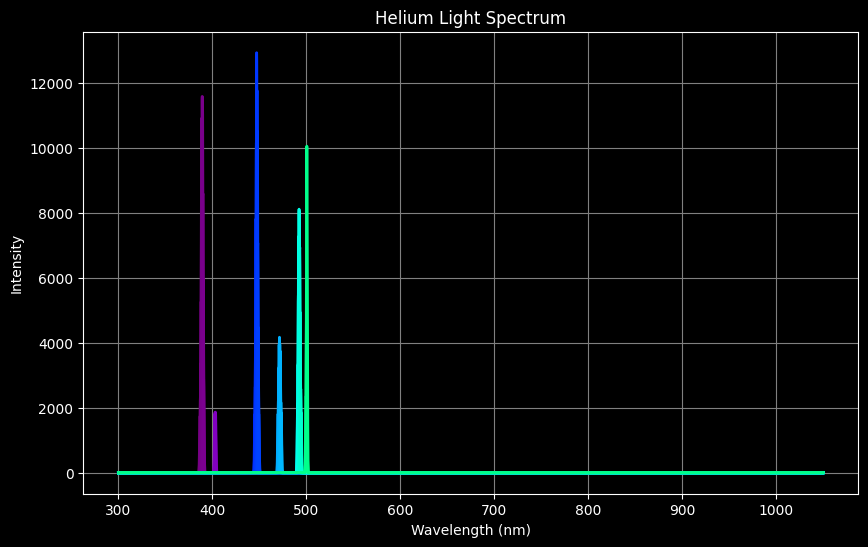

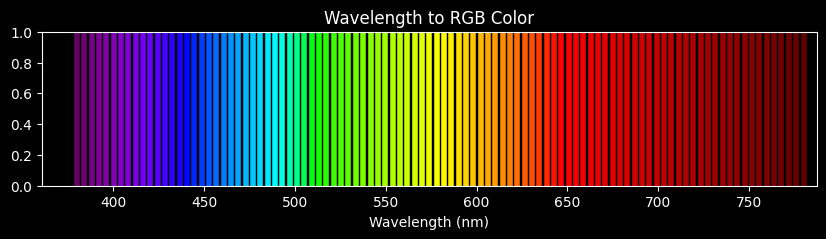

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def wavelength_to_rgb(wavelength):
    """Converts a wavelength in nm to an RGB color."""
    gamma = 0.8
    intensity_max = 255
    factor = 0.0
    R = G = B = 0
    
    if (wavelength >= 380) and (wavelength < 440):
        R = -(wavelength - 440) / (440 - 380)
        G = 0.0
        B = 1.0
    elif (wavelength >= 440) and (wavelength < 490):
        R = 0.0
        G = (wavelength - 440) / (490 - 440)
        B = 1.0
    elif (wavelength >= 490) and (wavelength < 510):
        R = 0.0
        G = 1.0
        B = -(wavelength - 510) / (510 - 490)
    elif (wavelength >= 510) and (wavelength < 580):
        R = (wavelength - 510) / (580 - 510)
        G = 1.0
        B = 0.0
    elif (wavelength >= 580) and (wavelength < 645):
        R = 1.0
        G = -(wavelength - 645) / (645 - 580)
        B = 0.0
    elif (wavelength >= 645) and (wavelength <= 780):
        R = 1.0
        G = 0.0
        B = 0.0
    
    if (wavelength >= 380) and (wavelength < 420):
        factor = 0.3 + 0.7*(wavelength - 380) / (420 - 380)
    elif (wavelength >= 420) and (wavelength < 645):
        factor = 1.0
    elif (wavelength >= 645) and (wavelength <= 780):
        factor = 0.3 + 0.7*(780 - wavelength) / (780 - 645)
    
    R = round(intensity_max * (R * factor)**gamma)
    G = round(intensity_max * (G * factor)**gamma)
    B = round(intensity_max * (B * factor)**gamma)
    
    return (R / 255, G / 255, B / 255)

def create_helium_spectrum():

    # Read the text file into a DataFrame
    data = pd.read_csv('Helium_S_data.txt', delimiter='\s+')

    # Extract the wavelength and intensity data
    helium_lines = data['Wave_L'].values
    intensities = data['Intensity'].values

    
 # Create a wavelength range from 300 nm to 1050 nm
    wavelength = np.linspace(300, 1050, 5000)
    spectrum = np.zeros_like(wavelength)

    # Plot the spectrum
    plt.figure(figsize=(10, 6))
    plt.style.use('dark_background')  # Set the plot style to dark background

    # Add the helium emission lines to the spectrum
    for line, intensity in zip(helium_lines, intensities):
        if intensity >= 1750:  # Only plot if intensity is greater than or equal to 1750
            color = wavelength_to_rgb(line)
            peak = intensity * np.exp(-0.5 * ((wavelength - line) / 0.5)**2)
            plt.plot(wavelength, peak, color=color, linewidth=2)

    plt.xlabel('Wavelength (nm)')
    plt.ylabel('Intensity')
    plt.title('Helium Light Spectrum')
    plt.grid(True, color='gray')  # Set the grid color to gray
    plt.show()

def verify_wavelength_colors():
    wavelengths = np.linspace(380, 780, 100)
    colors = [wavelength_to_rgb(w) for w in wavelengths]

    plt.figure(figsize=(10, 2))
    for w, color in zip(wavelengths, colors):
        plt.axvline(w, color=color, linewidth=4)
    plt.xlabel('Wavelength (nm)')
    plt.title('Wavelength to RGB Color')
    plt.show()

create_helium_spectrum()
verify_wavelength_colors()
